# 01 · Spectra and the log-λ grid

**What you'll learn**

- why a Doppler shift is a simple *translation* when wavelengths are spaced evenly in ln λ
- how to build a log-λ grid (`unicor.log_lambda_grid`) and resample a `Spectrum` onto one
- why resampling onto a finer grid adds no information, and how SPARTA keeps track of the
  native pixel size (`native_steps`)
- air vs vacuum wavelengths, and why mixing them is a large velocity error

In [1]:
import copy

import numpy as np
import matplotlib.pyplot as plt

import unicor
from sparta import Observations, Template

plt.rcParams.update({
    "figure.figsize": (8, 3.2), "figure.dpi": 100, "figure.constrained_layout.use": True,
    "font.size": 11, "axes.titlesize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
c = unicor.C_KMS                     # speed of light, km/s

## 1. A Doppler shift is a translation in ln λ

A star moving away at velocity $v$ shifts every wavelength by the same *factor*:
$\lambda_{\rm obs} = \lambda_{\rm rest}\,(1 + v/c)$. In wavelength the shift therefore grows with
λ. In $\ln\lambda$ it is the same constant, $\ln(1 + v/c)$, for every line:

In [2]:
v = 30.0                                       # km/s
rest = np.array([4000.0, 5500.0, 7000.0])      # Å
observed = unicor.doppler_shift_wave(rest, v)

print("shift in λ (Å):          ", np.round(observed - rest, 3))
print("shift in c·ln λ (km/s):  ", np.round(c * np.log(observed / rest), 4))

shift in λ (Å):           [0.4  0.55 0.7 ]
shift in c·ln λ (km/s):   [29.9985 29.9985 29.9985]


So on a grid with a constant step in $\ln\lambda$ (a constant *velocity* step), a Doppler shift
moves the whole spectrum by the same number of pixels. That is what lets a cross-correlation
(notebook 02) or a Fourier phase shift (notebook 03) measure a velocity.

## 2. Building a log-λ grid

`unicor.log_lambda_grid(lo, hi, dv)` returns wavelengths whose step is `dv` km/s in velocity. The
step in Å grows along the grid; the step in velocity does not.

In [3]:
wave, u = unicor.log_lambda_grid(5000.0, 5010.0, dv=0.5)

print(f"{wave.size} pixels")
print("step in Å at the two ends:      ", np.round(np.diff(wave)[[0, -1]], 6))
print("step in km/s at the two ends:   ", np.round(c * np.diff(np.log(wave))[[0, -1]], 6))
print("unicor.log_grid_step(wave) =", unicor.log_grid_step(wave), "km/s  (it also checks uniformity)")

1198 pixels
step in Å at the two ends:       [0.008339 0.008356]
step in km/s at the two ends:    [0.5 0.5]
unicor.log_grid_step(wave) = 0.5000000000000088 km/s  (it also checks uniformity)


Now a toy spectrum with three absorption lines. We Doppler-shift it by the velocity that
corresponds to exactly 7 pixels, and compare with simply rolling the array by 7 pixels.

In [4]:
def toy_spectrum(wave):
    """Three Gaussian absorption lines (σ = 0.05 Å) on a continuum of 1."""
    centres, depth, sigma = (5003.0, 5005.2, 5007.9), 0.6, 0.05
    return 1 - sum(depth * np.exp(-0.5 * ((wave - c0) / sigma) ** 2) for c0 in centres)

k = 7
v_k = unicor.velocity_from_log_shift(k * unicor.log_grid_dln(wave))     # km/s, 'cz' convention
shifted = toy_spectrum(wave / unicor.doppler_factor(v_k))               # the shifted spectrum
rolled = np.roll(toy_spectrum(wave), k)                                 # just move the pixels

print(f"7 pixels of 0.5 km/s correspond to v = {v_k:.5f} km/s")
print(f"max |Doppler-shifted - rolled| (interior) = {np.max(np.abs(shifted - rolled)[k:]):.1e}")

7 pixels of 0.5 km/s correspond to v = 3.50002 km/s
max |Doppler-shifted - rolled| (interior) = 9.7e-12


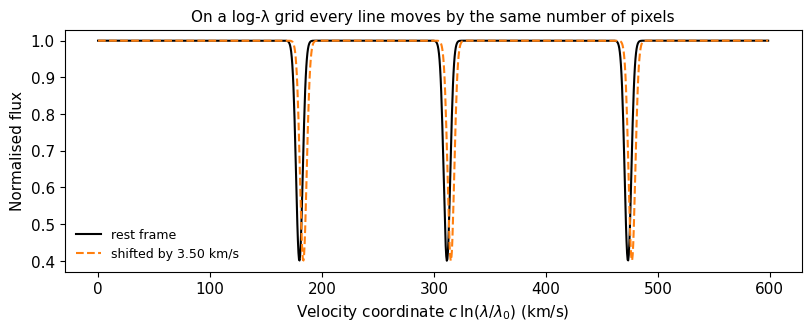

In [5]:
fig, ax = plt.subplots()
ax.plot(u, toy_spectrum(wave), "k", label="rest frame")
ax.plot(u, shifted, "tab:orange", ls="--", label=f"shifted by {v_k:.2f} km/s")
ax.set_xlabel(r"Velocity coordinate $c\,\ln(\lambda/\lambda_0)$ (km/s)")
ax.set_ylabel("Normalised flux")
ax.set_title("On a log-λ grid every line moves by the same number of pixels")
ax.legend()
plt.show()

Note the velocity is 3.50002 km/s, not 3.5: a shift of $k$ pixels is
$\ln(1 + v/c) = k\,\Delta$, so $v = c\,(e^{k\Delta} - 1)$. This is the IAU "cz" convention that
SPARTA uses by default; the engines do the conversion for you (more in notebook 02).

## 3. Real spectra: `Spectrum.interpolate(method='log')`

Archive spectra rarely come on a log-λ grid. The HARPS 1-D product has a constant 0.01 Å step,
so its *velocity* step drifts across the window:

In [6]:
harps = Observations(survey="HARPS", target_visits_lib="data/TOI193/", min_wv=4990, max_wv=5090)
spec = harps.spec_list[0]
w = spec.wv[0]

print("archive step (Å) at the two ends:    ", np.round(np.diff(w)[[0, -1]], 4))
print("archive step (km/s) at the two ends: ", np.round(c * np.diff(w)[[0, -1]] / w[[0, -1]], 4))
print("native (detector) step recorded:     ", np.round(spec.native_steps(), 4), "km/s")

archive step (Å) at the two ends:     [0.01 0.01]
archive step (km/s) at the two ends:  [0.6008 0.589 ]
native (detector) step recorded:      [0.6093] km/s


`interpolate(delta=dv, method='log')` resamples every order onto a log-λ grid with step `dv`
(km/s) and records it in `Info`. (It works in place and returns the spectrum, so we resample a copy.)

In [7]:
log_spec = copy.deepcopy(spec).interpolate(delta=0.1, method="log")

print("grid:", log_spec.Info["GridType"], log_spec.Info["GridDelta"])
print(f"velocity step now: {unicor.log_grid_step(log_spec.wv[0]):.6f} km/s")
print(f"pixels: {len(spec.wv[0])} -> {len(log_spec.wv[0])}")
print("native step, still:", np.round(log_spec.native_steps(), 4), "km/s")

grid: log 0.1 km / s
velocity step now: 0.100000 km/s
pixels: 10000 -> 59467
native step, still: [0.6093] km/s


## 4. Resampling does not add information

The new grid has six times more pixels, but neighbouring resampled pixels are interpolated
from the *same* native pixels, so their noise is shared. A quick Monte Carlo: white noise on a
native grid of 0.6 km/s, resampled (cubic spline) onto 0.1 km/s.

In [8]:
rng = np.random.default_rng(1)
w_native, _ = unicor.log_lambda_grid(5000.0, 5005.0, dv=0.6)
w_fine, _ = unicor.log_lambda_grid(w_native[1], w_native[-2], dv=0.1)    # strictly inside

noise = rng.standard_normal((2000, w_native.size))                      # 2000 trials
fine = np.array([unicor.resample(w_native, n, w_fine, kind="cubic") for n in noise])

lag1 = np.mean(fine[:, :-1] * fine[:, 1:]) / np.mean(fine ** 2)
print(f"{w_native.size} native pixels -> {w_fine.size} resampled pixels")
print(f"correlation of neighbouring resampled pixels: {lag1:.2f}")
print(f"scatter of the mean over all pixels:  measured {np.std(fine.mean(axis=1)):.4f}")
print(f"    if the {w_native.size} native pixels count:     {1 / np.sqrt(w_native.size):.4f}")
print(f"    if the {w_fine.size} resampled pixels counted: {1 / np.sqrt(w_fine.size):.4f}")

500 native pixels -> 2982 resampled pixels
correlation of neighbouring resampled pixels: 0.96
scatter of the mean over all pixels:  measured 0.0455
    if the 500 native pixels count:     0.0447
    if the 2982 resampled pixels counted: 0.0183


The average is only as precise as the native pixels allow. The same holds for an RV: its
uncertainty must count **native** pixels. That is why every resampling records the coarsest
step the spectrum has had in `Info['NativeStep']` (read with `native_steps()`), and why
`Observations` seeds it with the detector step for archive-resampled products such as HARPS.
The RV engines then count `n_pix × min(1, dv / native_step)` independent pixels:

In [9]:
native = log_spec.native_steps()[0]
n_eff = len(log_spec.wv[0]) * min(1.0, 0.1 / native)
n_detector = c * np.log(w[-1] / w[0]) / native

print(f"independent pixels counted by SPARTA: {n_eff:.0f}")
print(f"detector pixels across the window:    {n_detector:.0f}")

independent pixels counted by SPARTA: 9759
detector pixels across the window:    9761


## 5. Air vs vacuum

Wavelengths can be measured in air or in vacuum, and the two differ by the refractive index of
air, $\lambda_{\rm air} = \lambda_{\rm vac}/n$ with $n - 1 \approx 2.8\times10^{-4}$ in the optical. As a
velocity that is $c\,(n-1) \approx 83$ km/s, so correlating an air spectrum against a vacuum
template gives an RV off by ~83 km/s (and slightly different from order to order). PHOENIX
models are in vacuum; `Template.from_phoenix(..., air=True)` converts them to air (Morton 2000).
Here is one strong line in both frames:

In [10]:
vac = Template.from_phoenix(5800, 3.5, 0.5, wave_range=(5150, 6600))
air = Template.from_phoenix(5800, 3.5, 0.5, wave_range=(5150, 6600), air=True)

def deepest(template, lo, hi):
    """Wavelength (Å) of the lowest-flux pixel between lo and hi."""
    wv, fl = template.model.wv[0], template.model.sp[0]
    inside = (wv > lo) & (wv < hi)
    return wv[inside][np.argmin(fl[inside])]

for line, (lo, hi) in {"Mg b": (5182.0, 5187.0), "H-alpha": (6560.0, 6567.0)}.items():
    lv, la = deepest(vac, lo, hi), deepest(air, lo, hi)
    print(f"{line:8s} vacuum {lv:.3f} Å, air {la:.3f} Å  ->  c (λvac/λair - 1) = {c * (lv / la - 1):.2f} km/s")

Mg b     vacuum 5185.050 Å, air 5183.606 Å  ->  c (λvac/λair - 1) = 83.50 km/s
H-alpha  vacuum 6564.630 Å, air 6562.817 Å  ->  c (λvac/λair - 1) = 82.82 km/s


Each product records its frame (notebook 00): HARPS is in air, so a PHOENIX template for it
needs `air=True`. The NRES product used here does not document its frame (`None`), so its
absolute RV zero point depends on that choice; RV *differences* between epochs do not.

## Summary / next

- On a log-λ grid a Doppler shift is a translation: the basis of every RV engine in SPARTA.
- `unicor.log_lambda_grid` builds such a grid; `Spectrum.interpolate(delta=dv, method='log')`
  resamples a spectrum onto one.
- Resampling adds samples, not information; SPARTA counts native pixels via `native_steps()`.
- Air and vacuum wavelengths differ by ~83 km/s; match the template's frame to the data's.

**Next:** `02_radial_velocity_unicor.ipynb`: measuring a radial velocity with a cross-correlation.